In [2]:
import importlib
import nystrom_functions
importlib.reload(nystrom_functions)

import numpy as np
import matplotlib.pyplot as plt
import time
import pandas as pd

from sklearn.preprocessing import StandardScaler
from KRR_utils import *
from nystrom_functions import *

In [3]:
# data setup and full KRR baseline

df = pd.read_csv("../Data/CASP.csv")
X = df.iloc[:, 1:].to_numpy(dtype=float)
y = df.iloc[:, 0].to_numpy(dtype=float)

cycles = 5  
split_seed = 1  # the train/test data split remain fixed across all repetitions
method_seed = 1000  # starting seed for Nystrom methods
split_rng = np.random.default_rng(split_seed)  

# sample sizes for training and testing
n_train = 19000 #add 0
n_test = 1000

# this is the KRR lambda in (K + lambda I) * alpha = y
krr_lam = 1e-2

# sampled columns for uniform and approximate leverage
l_values = [50, 100, 200, 400, 800, 1600]

# this is the recursive parameter, not the same lamda for some reason
rec_lam_values = [1000, 2000, 5000, 10000, 20000] #add 0
rec_delta = 0.1
rec_base_size = None # for testing

# approximate leverage starts with these many uniform columns
ini_l_fixed = 100 #100

# this is a check that compares the factorized solver to an explicit solve of (K_tilde + lambda I) only used to verify the solver works
check_explicit_solve = False

ind = split_rng.choice(X.shape[0], size=n_train + n_test, replace=False)  

train_ind = ind[:n_train]
test_ind = ind[n_train:]
X_train_raw = X[train_ind]
y_train = y[train_ind]
X_test_raw = X[test_ind]
y_test = y[test_ind]

# free the complete dataset after making the fixed split 
del df, X, y

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

gamma = 1 / X_train.shape[1]

def rbf_final(A, B):
    K = rbf(A, B, gamma=gamma)
    return K

def get_mse(y_true, y_pred):
    err = np.mean((y_true - y_pred)**2)
    return err

dataset = "CASP"

print("cycles =", cycles)
print("n_train =", n_train)
print("n_test =", n_test)
print("krr lambda =", krr_lam)
print("gamma =", gamma)

# full kernel direct form
start_time = time.perf_counter()
K_train = rbf_final(X_train, X_train)
K_test = rbf_final(X_test, X_train)
full_kernel_time = time.perf_counter() - start_time
full_solve_times = []

for cycle in range(cycles):
    print("full KRR cycle", cycle + 1, "of", cycles)

    start_time = time.perf_counter()

    alpha_full = np.linalg.solve(
        K_train + krr_lam*np.eye(n_train),
        y_train
    )
    y_hat_full = K_test @ alpha_full

    full_solve_times.append(time.perf_counter() - start_time)

full_solve_time = np.mean(full_solve_times)
full_solve_variance = np.var(full_solve_times, ddof=1)
full_solve_std = np.std(full_solve_times, ddof=1)
full_total_time = full_kernel_time + full_solve_time
full_mse = get_mse(y_test, y_hat_full)

K_norm = np.linalg.norm(K_train, ord="fro")
y_norm = np.linalg.norm(y_train)
alpha_norm = np.linalg.norm(alpha_full)

print("full KRR mse =", full_mse)
print("full kernel time =", full_kernel_time)
print("mean full solve time =", full_solve_time)
print("full solve time variance =", full_solve_variance)
print("full solve time std =", full_solve_std)
print("full total time with mean solve time =", full_total_time)

cycles = 5
n_train = 19000
n_test = 1000
krr lambda = 0.01
gamma = 0.1111111111111111
full KRR cycle 1 of 5
full KRR cycle 2 of 5
full KRR cycle 3 of 5
full KRR cycle 4 of 5
full KRR cycle 5 of 5
full KRR mse = 18.979734606458667
full kernel time = 6.152998699999898
mean full solve time = 17.84903869999989
full solve time variance = 0.006099014986863618
full solve time std = 0.07809619060404686
full total time with mean solve time = 24.00203739999979


In [4]:
# uniform and approximate leverage experiments

rows = []

for cycle in range(1, cycles + 1):
    print("cycle", cycle, "of", cycles, " uniform and approximate leverage")
    uniform_rng = np.random.default_rng(method_seed + cycle)
    approx_rng = np.random.default_rng(method_seed + cycle + 1000)

    for l in l_values:
        print("")
        print("l =", l)

        # uniform sampling
        
        print("uniform")

        start_time = time.perf_counter()
        uni_ind = uniform_sampling(n_train, l, uniform_rng)  
        sample_time = time.perf_counter() - start_time

        start_time = time.perf_counter()
        alpha_uni, y_hat_uni, U_uni, eig_uni, C_uni, W_uni = solver(
            X_train,
            rbf_final,
            uni_ind,
            y_train,
            krr_lam,
            X_test=X_test,
            return_factors=True
        )
        solve_time = time.perf_counter() - start_time

        K_uni = (U_uni * eig_uni) @ U_uni.T

        uni_kernel_err = np.linalg.norm(K_train - K_uni, ord="fro") / K_norm
        uni_alpha_err = np.linalg.norm(alpha_full - alpha_uni) / alpha_norm
        uni_mse = get_mse(y_test, y_hat_uni)

        if check_explicit_solve:
            alpha_uni_explicit = np.linalg.solve(K_uni + krr_lam*np.eye(n_train), y_train)
            uni_solver_err = np.linalg.norm(alpha_uni - alpha_uni_explicit) / np.linalg.norm(alpha_uni_explicit)
        else:
            uni_solver_err = np.nan

        rows.append([
            cycle,
            l,
            "uniform",
            np.nan, #empty column for rls
            uni_kernel_err,
            uni_alpha_err,
            uni_solver_err,
            uni_mse,
            sample_time,
            solve_time,
            sample_time + solve_time
        ])

        print("kernel error =", uni_kernel_err)
        print("alpha error =", uni_alpha_err)
        print("test mse =", uni_mse)
        print("sample_time =", sample_time)
        print("solve_time =", solve_time)
        print("time =", sample_time + solve_time)


        # approximate leverage sampling
        
        print("approx leverage")

        ini_l = min(ini_l_fixed, max(1, l // 2))
        extra_l = l - ini_l

        start_time = time.perf_counter()
        app_ind, app_scores, ini_ind = approximate_leverage_kernel(
            X_train,
            rbf_final,
            ini_l,
            extra_l,
            approx_rng
        )
        sample_time = time.perf_counter() - start_time

        start_time = time.perf_counter()
        alpha_app, y_hat_app, U_app, eig_app, C_app, W_app = solver(
            X_train,
            rbf_final,
            app_ind,
            y_train,
            krr_lam,
            X_test=X_test,
            return_factors=True
        )
        solve_time = time.perf_counter() - start_time

        K_app = (U_app * eig_app) @ U_app.T

        app_kernel_err = np.linalg.norm(K_train - K_app, ord="fro") / K_norm
        app_alpha_err = np.linalg.norm(alpha_full - alpha_app) / alpha_norm
        app_mse = get_mse(y_test, y_hat_app)

        if check_explicit_solve:
            alpha_app_explicit = np.linalg.solve(K_app + krr_lam*np.eye(n_train), y_train)
            app_solver_err = np.linalg.norm(alpha_app - alpha_app_explicit) / np.linalg.norm(alpha_app_explicit)
        else:
            app_solver_err = np.nan

        rows.append([
            cycle,
            len(app_ind),
            "approx leverage",
            np.nan,
            app_kernel_err,
            app_alpha_err,
            app_solver_err,
            app_mse,
            sample_time,
            solve_time,
            sample_time + solve_time
        ])

        print("kernel error =", app_kernel_err)
        print("alpha error =", app_alpha_err)
        print("test mse =", app_mse)
        print("sample_time =", sample_time)
        print("solve_time =", solve_time)
        print("time =", sample_time + solve_time)

cycle 1 of 5  uniform and approximate leverage

l = 50
uniform
kernel error = 0.031924593683154416
alpha error = 0.592658599088632
test mse = 25.32331050443623
sample_time = 0.0001544000001558743
solve_time = 0.06504910000012387
time = 0.06520350000027975
approx leverage
kernel error = 0.019813063918807446
alpha error = 0.5904519152007967
test mse = 25.24709417113977
sample_time = 0.09068919999981517
solve_time = 0.053640399999949295
time = 0.14432959999976447

l = 100
uniform
kernel error = 0.0077309202800938375
alpha error = 0.45432518001466543
test mse = 22.931580123503867
sample_time = 6.380000013450626e-05
solve_time = 0.16514860000006593
time = 0.16521240000020043
approx leverage
kernel error = 0.018194120528714084
alpha error = 0.4972833837288992
test mse = 23.45004373723011
sample_time = 0.17447830000037357
solve_time = 0.1509885000000395
time = 0.32546680000041306

l = 200
uniform
kernel error = 0.0048699614688104435
alpha error = 0.3450594641379784
test mse = 21.1618641209931

In [5]:
# recursive RLS
k_diag_train = np.diag(K_train).copy()

for cycle in range(1, cycles + 1):
    print("main experiment cycle", cycle, "of", cycles, "- recursive RLS")
    recursive_rng = np.random.default_rng(method_seed + cycle + 2000)

    for rec_lam in rec_lam_values:
        print("")
        print("recursive RLS, rec_lam =", rec_lam)

        start_time = time.perf_counter()
        rec_ind, rec_weight = recursive_nystrom(
            X_train,
            rbf_final,
            rec_lam,
            rec_delta,
            recursive_rng,
            k_diag_train,
            rec_base_size
        )
        sample_time = time.perf_counter() - start_time

        start_time = time.perf_counter()
        alpha_rec, y_hat_rec, U_rec, eig_rec, C_rec, W_rec = solver(
            X_train,
            rbf_final,
            rec_ind,
            y_train,
            krr_lam,
            X_test=X_test,
            return_factors=True
        )
        solve_time = time.perf_counter() - start_time

        K_rec = (U_rec * eig_rec) @ U_rec.T

        rec_kernel_err = np.linalg.norm(K_train - K_rec, ord="fro") / K_norm
        rec_alpha_err = np.linalg.norm(alpha_full - alpha_rec) / alpha_norm
        rec_mse = get_mse(y_test, y_hat_rec)

        if check_explicit_solve:
            alpha_rec_explicit = np.linalg.solve(K_rec + krr_lam*np.eye(n_train), y_train)
            rec_solver_err = np.linalg.norm(alpha_rec - alpha_rec_explicit) / np.linalg.norm(alpha_rec_explicit)
        else:
            rec_solver_err = np.nan

        rows.append([
            cycle,
            len(rec_ind),
            "recursive RLS",
            rec_lam,
            rec_kernel_err,
            rec_alpha_err,
            rec_solver_err,
            rec_mse,
            sample_time,
            solve_time,
            sample_time + solve_time
        ])

        print("selected columns =", len(rec_ind))
        print("kernel error =", rec_kernel_err)
        print("alpha error =", rec_alpha_err)
        print("test mse =", rec_mse)
        print("sample_time =", sample_time)
        print("solve_time =", solve_time)
        print("time =", sample_time + solve_time)

main experiment cycle 1 of 5 - recursive RLS

recursive RLS, rec_lam = 1000
selected columns = 1020
kernel error = 0.0009408855247676284
alpha error = 0.13429513082246655
test mse = 19.152759495668295
sample_time = 1.7649278999997478
solve_time = 3.4250868999997692
time = 5.190014799999517

recursive RLS, rec_lam = 2000
selected columns = 547
kernel error = 0.001586241357638815
alpha error = 0.18621368778958514
test mse = 19.284998620294626
sample_time = 0.9541309999999612
solve_time = 1.9848394000000553
time = 2.9389704000000165

recursive RLS, rec_lam = 5000
selected columns = 264
kernel error = 0.006632827738547789
alpha error = 0.29401367754734387
test mse = 20.64907319008287
sample_time = 0.7735374999997475
solve_time = 0.5537967000000208
time = 1.3273341999997683

recursive RLS, rec_lam = 10000
selected columns = 131
kernel error = 0.009503456208659396
alpha error = 0.4367368285673054
test mse = 22.97003375493786
sample_time = 0.5734166000002006
solve_time = 0.20936399999982314
t

In [2]:
# table

columns = [
    "cycle",
    "l",
    "method",
    "rec_lam",
    "relative_kernel_error",
    "relative_alpha_error",
    "explicit_solver_error",
    "test_mse",
    "sample_time",
    "solve_time",
    "total_time"
]

results = pd.DataFrame(rows, columns=columns)
results["test_rmse"] = np.sqrt(results["test_mse"])  # RMSE is calculated separately for every trial
results["relative_excess_rmse"] = (results["test_rmse"] - np.sqrt(full_mse)) / np.sqrt(full_mse)
results["parameter"] = results["l"]
results.loc[results["method"] == "recursive RLS", "parameter"] = results.loc[results["method"] == "recursive RLS", "rec_lam"]

summary_results = results.groupby(["method", "parameter"], as_index=False).agg(
    l_mean=("l", "mean"),  # recursive RLS is placed at its average selected column count
    l_variance=("l", "var"),
    l_std=("l", "std"),
    relative_kernel_error_mean=("relative_kernel_error", "mean"),  # empirical expectation
    relative_kernel_error_variance=("relative_kernel_error", "var"),  # sample variance
    relative_kernel_error_std=("relative_kernel_error", "std"),
    relative_alpha_error_mean=("relative_alpha_error", "mean"),
    relative_alpha_error_variance=("relative_alpha_error", "var"),
    relative_alpha_error_std=("relative_alpha_error", "std"),
    test_mse_mean=("test_mse", "mean"),
    test_mse_variance=("test_mse", "var"),
    test_mse_std=("test_mse", "std"),
    test_rmse_mean=("test_rmse", "mean"),
    test_rmse_variance=("test_rmse", "var"),
    test_rmse_std=("test_rmse", "std"),
    relative_excess_rmse_mean=("relative_excess_rmse", "mean"),
    relative_excess_rmse_variance=("relative_excess_rmse", "var"),
    relative_excess_rmse_std=("relative_excess_rmse", "std"),
    sample_time_mean=("sample_time", "mean"),
    sample_time_variance=("sample_time", "var"),
    sample_time_std=("sample_time", "std"),
    solve_time_mean=("solve_time", "mean"),
    solve_time_variance=("solve_time", "var"),
    solve_time_std=("solve_time", "std"),
    total_time_mean=("total_time", "mean"),
    total_time_variance=("total_time", "var"),
    total_time_std=("total_time", "std")
)

results.to_csv("../Results/" + dataset + "final_cycleed_raw_results.csv", index=False)
summary_results.to_csv("../Results/" + dataset + "final_cycleed_summary_results.csv", index=False)

print("individual cycleed runs")
display(results)
print("expectation, variance, and standard deviation")
summary_results

NameError: name 'pd' is not defined

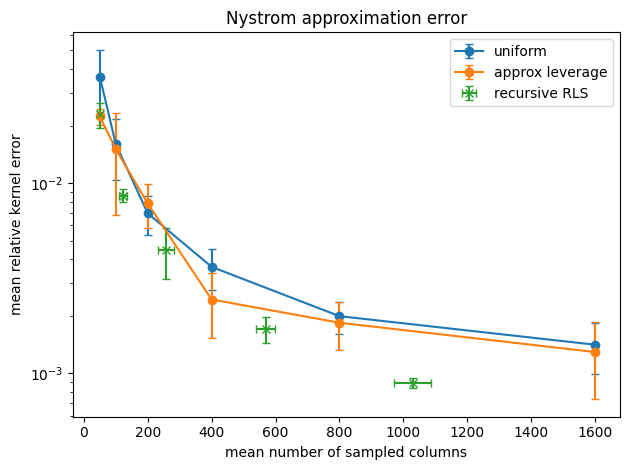

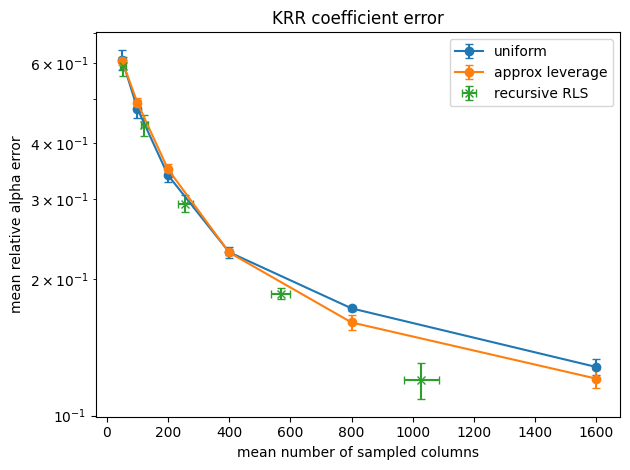

In [ ]:
# main plots

plot_df = summary_results.copy()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l_mean")
    plt.errorbar(sub["l_mean"], sub["relative_kernel_error_mean"], yerr=sub["relative_kernel_error_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["l_mean"], sub["relative_kernel_error_mean"], xerr=sub["l_std"], yerr=sub["relative_kernel_error_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.yscale("log")
plt.xlabel("mean number of sampled columns")
plt.ylabel("mean relative kernel error")
plt.title("Nystrom approximation error")
plt.legend()
plt.tight_layout()
plt.savefig("../Results/" + dataset + "final_kernel_error_vs_l.pdf")
plt.show()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l_mean")
    plt.errorbar(sub["l_mean"], sub["relative_alpha_error_mean"], yerr=sub["relative_alpha_error_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["l_mean"], sub["relative_alpha_error_mean"], xerr=sub["l_std"], yerr=sub["relative_alpha_error_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.yscale("log")
plt.xlabel("mean number of sampled columns")
plt.ylabel("mean relative alpha error")
plt.title("KRR coefficient error")
plt.legend()
plt.tight_layout()
plt.savefig("../Results/" + dataset + "final_alpha_error_vs_l.pdf")
plt.show()

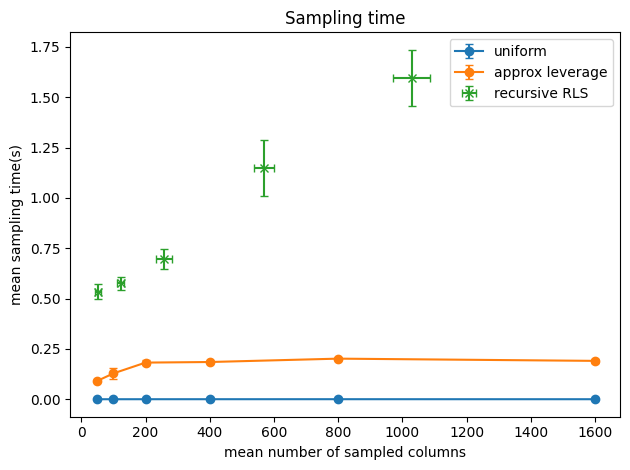

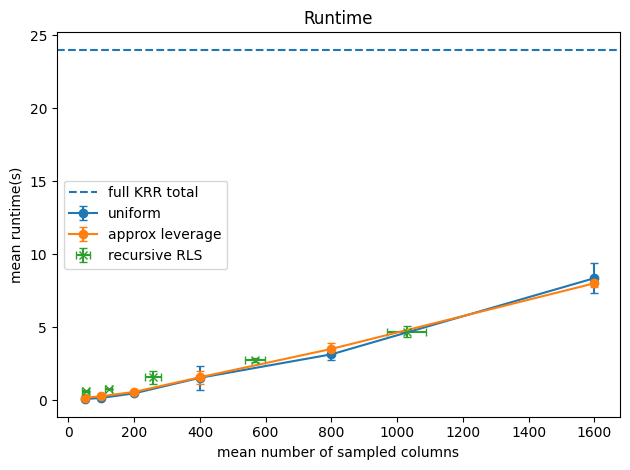

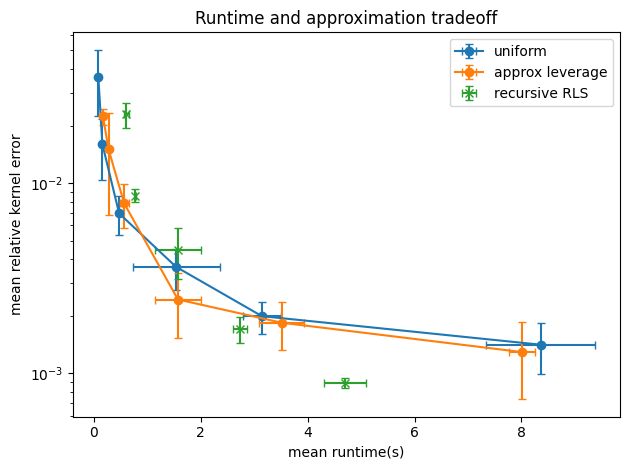

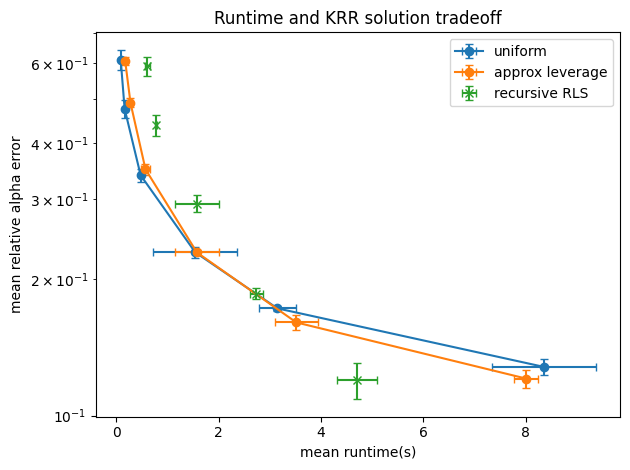

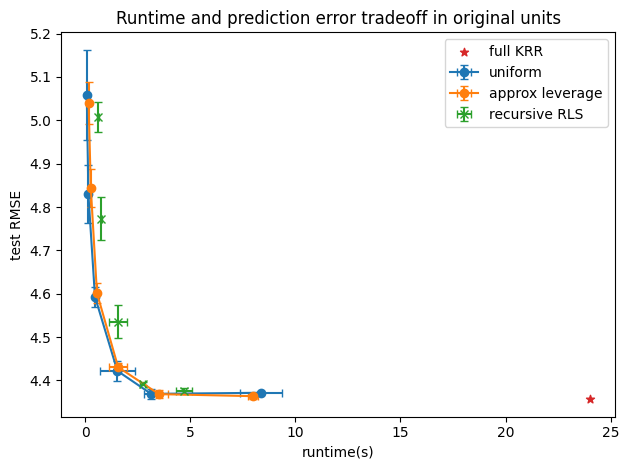

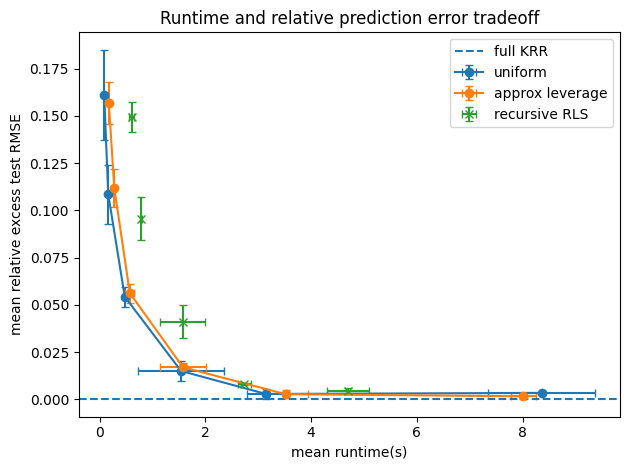

In [6]:
# runtime plots

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l_mean")
    plt.errorbar(sub["l_mean"], sub["sample_time_mean"], yerr=sub["sample_time_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["l_mean"], sub["sample_time_mean"], xerr=sub["l_std"], yerr=sub["sample_time_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.xlabel("mean number of sampled columns")
plt.ylabel("mean sampling time(s)")
plt.title("Sampling time")
plt.legend()
plt.tight_layout()
plt.savefig("../Results/" + dataset + "final_sample_time_vs_l.pdf")
plt.show()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l_mean")
    plt.errorbar(sub["l_mean"], sub["total_time_mean"], yerr=sub["total_time_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["l_mean"], sub["total_time_mean"], xerr=sub["l_std"], yerr=sub["total_time_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.axhline(full_total_time, linestyle="--", label="full KRR total")
plt.xlabel("mean number of sampled columns")
plt.ylabel("mean runtime(s)")
plt.title("Runtime")
plt.legend()
plt.tight_layout()
plt.savefig("../Results/" + dataset + "final_total_time_vs_l.pdf")
plt.show()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("total_time_mean")
    plt.errorbar(sub["total_time_mean"], sub["relative_kernel_error_mean"], xerr=sub["total_time_std"], yerr=sub["relative_kernel_error_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["total_time_mean"], sub["relative_kernel_error_mean"], xerr=sub["total_time_std"], yerr=sub["relative_kernel_error_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.yscale("log")
plt.xlabel("mean runtime(s)")
plt.ylabel("mean relative kernel error")
plt.title("Runtime and approximation tradeoff")
plt.legend()
plt.tight_layout()
plt.savefig("../Results/" + dataset + "final_runtime_kernel_error_tradeoff.pdf")
plt.show()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("total_time_mean")
    plt.errorbar(sub["total_time_mean"], sub["relative_alpha_error_mean"], xerr=sub["total_time_std"], yerr=sub["relative_alpha_error_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["total_time_mean"], sub["relative_alpha_error_mean"], xerr=sub["total_time_std"], yerr=sub["relative_alpha_error_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.yscale("log")
plt.xlabel("mean runtime(s)")
plt.ylabel("mean relative alpha error")
plt.title("Runtime and KRR solution tradeoff")
plt.legend()
plt.tight_layout()
plt.savefig("../Results/" + dataset + "final_runtime_alpha_error_tradeoff.pdf")
plt.show()
plt.figure()

for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("total_time_mean")

    plt.errorbar(
        sub["total_time_mean"],
        sub["test_rmse_mean"],
        xerr=sub["total_time_std"],
        yerr=sub["test_rmse_std"],
        marker="o",
        capsize=3,
        label=method
    )

sub = plot_df[plot_df["method"] == "recursive RLS"]

plt.errorbar(
    sub["total_time_mean"],
    sub["test_rmse_mean"],
    xerr=sub["total_time_std"],
    yerr=sub["test_rmse_std"],
    fmt="x",
    capsize=3,
    linestyle="none",
    label="recursive RLS"
)

plt.scatter(
    [full_total_time],
    [np.sqrt(full_mse)],
    marker="*",
    color="tab:red",
    label="full KRR"
)

plt.xlabel("runtime(s)")
plt.ylabel("test RMSE")
plt.title("Runtime and prediction error tradeoff in original units")
plt.legend()
plt.tight_layout()
plt.savefig("../Results/" + dataset + "final_runtime_test_rmse_tradeoff.pdf")
plt.show()
plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("total_time_mean")
    plt.errorbar(sub["total_time_mean"], sub["relative_excess_rmse_mean"], xerr=sub["total_time_std"], yerr=sub["relative_excess_rmse_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["total_time_mean"], sub["relative_excess_rmse_mean"], xerr=sub["total_time_std"], yerr=sub["relative_excess_rmse_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.axhline(0, linestyle="--", label="full KRR")
plt.xlabel("mean runtime(s)")
plt.ylabel("mean relative excess test RMSE")
plt.title("Runtime and relative prediction error tradeoff")
plt.legend()
plt.tight_layout()
plt.savefig("../Results/" + dataset + "final_runtime_relative_excess_rmse_tradeoff.pdf")
plt.show()

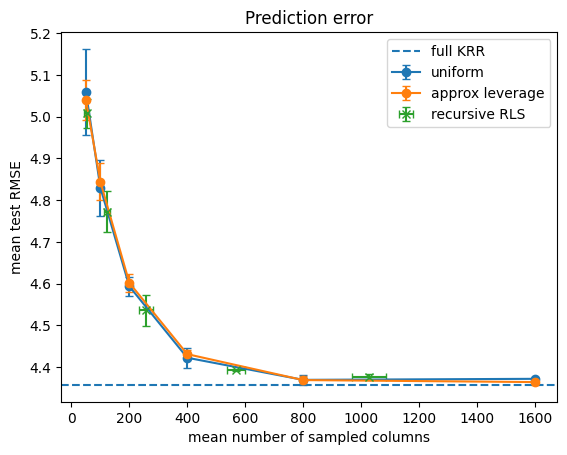

In [ ]:
# prediction error in original units

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l_mean")
    plt.errorbar(sub["l_mean"], sub["test_rmse_mean"], yerr=sub["test_rmse_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["l_mean"], sub["test_rmse_mean"], xerr=sub["l_std"], yerr=sub["test_rmse_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.axhline(np.sqrt(full_mse), linestyle="--", label="full KRR")
plt.xlabel("mean number of sampled columns")
plt.ylabel("mean test RMSE")
plt.title("Prediction error")
plt.legend()
plt.tight_layout()
plt.savefig("../Results/" + dataset + "final_test_rmse_vs_l.pdf")
plt.show()

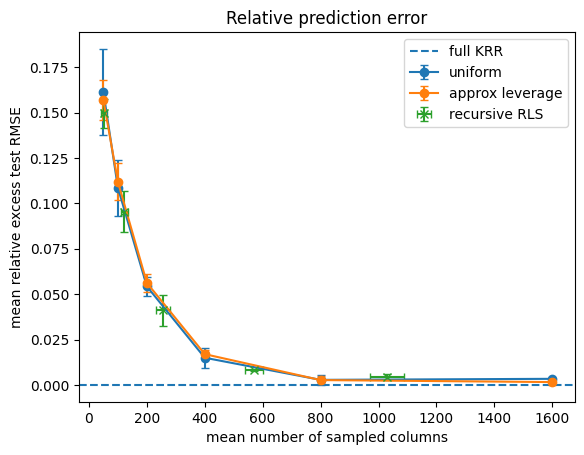

In [ ]:
# prediction error check

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l_mean")
    plt.errorbar(sub["l_mean"], sub["relative_excess_rmse_mean"], yerr=sub["relative_excess_rmse_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["l_mean"], sub["relative_excess_rmse_mean"], xerr=sub["l_std"], yerr=sub["relative_excess_rmse_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.axhline(0, linestyle="--", label="full KRR")
plt.xlabel("mean number of sampled columns")
plt.ylabel("mean relative excess test RMSE")
plt.title("Relative prediction error")
plt.legend()
plt.tight_layout()
plt.savefig("../Results/" + dataset + "final_relative_excess_rmse_vs_l.pdf")
plt.show()